Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# Clasificación de Imágenes Estudiante vs. Fondo con VGG-16 (Transfer Learning)


En este Jupyter Notebook, vamos a desarrollar un clasificador de imágenes utilizando la arquitectura de red neuronal convolucional (CNN) conocida como VGG-16. Este modelo ha demostrado ser muy efectivo en tareas de clasificación de imágenes.

El objetivo es distinguir entre imágenes que contienen el rostro del estudiante e imágenes de fondo (escenas, objetos y rostros de otras personas). En este contexto, las etiquetas son 1 para el estudiante y 0 para el fondo.

VGG-16 es una arquitectura de CNN propuesta por K. Simonyan y A. Zisserman de la Universidad de Oxford en el paper "Very Deep Convolutional Networks for Large-Scale Image Recognition". Esta red es caracterizada por su simplicidad, utilizando solo capas convolucionales 3x3 apiladas una sobre otra en profundidad creciente.

Vamos a entrenar nuestro modelo en este conjunto de datos y evaluar su rendimiento. A lo largo de este notebook, exploraremos diferentes aspectos del proceso de entrenamiento y optimización del modelo, así como también la evaluación de su rendimiento.

1. La clase **estudiante** (etiqueta 1) está en `datasets/fotos`: fotos del estudiante con y sin lentes, en distintas poses y ángulos.

2. La clase **fondo** (etiqueta 0) está en `datasets/fondos`: escenas y objetos (`BACKGROUND_Google` de Caltech-101), el entorno habitual del estudiante sin él, y rostros de otras personas (categoría `Faces` de Caltech-101, extraída de `datasets/archive.zip`, y una persona por identidad de Labeled Faces in the Wild, extraída de `datasets/lfw.tgz`).

3. Las imágenes para las 3 pruebas de la actividad se guardan en `datasets/prueba/` (subcarpetas `webcam`, `persona`, `fondo`, `rostros`) y nunca se usan para entrenar. `fondo` y `rostros` se completan automáticamente con imágenes de `BACKGROUND_Google` no usadas en el entrenamiento y con rostros LFW de identidades que tampoco están en el entrenamiento.

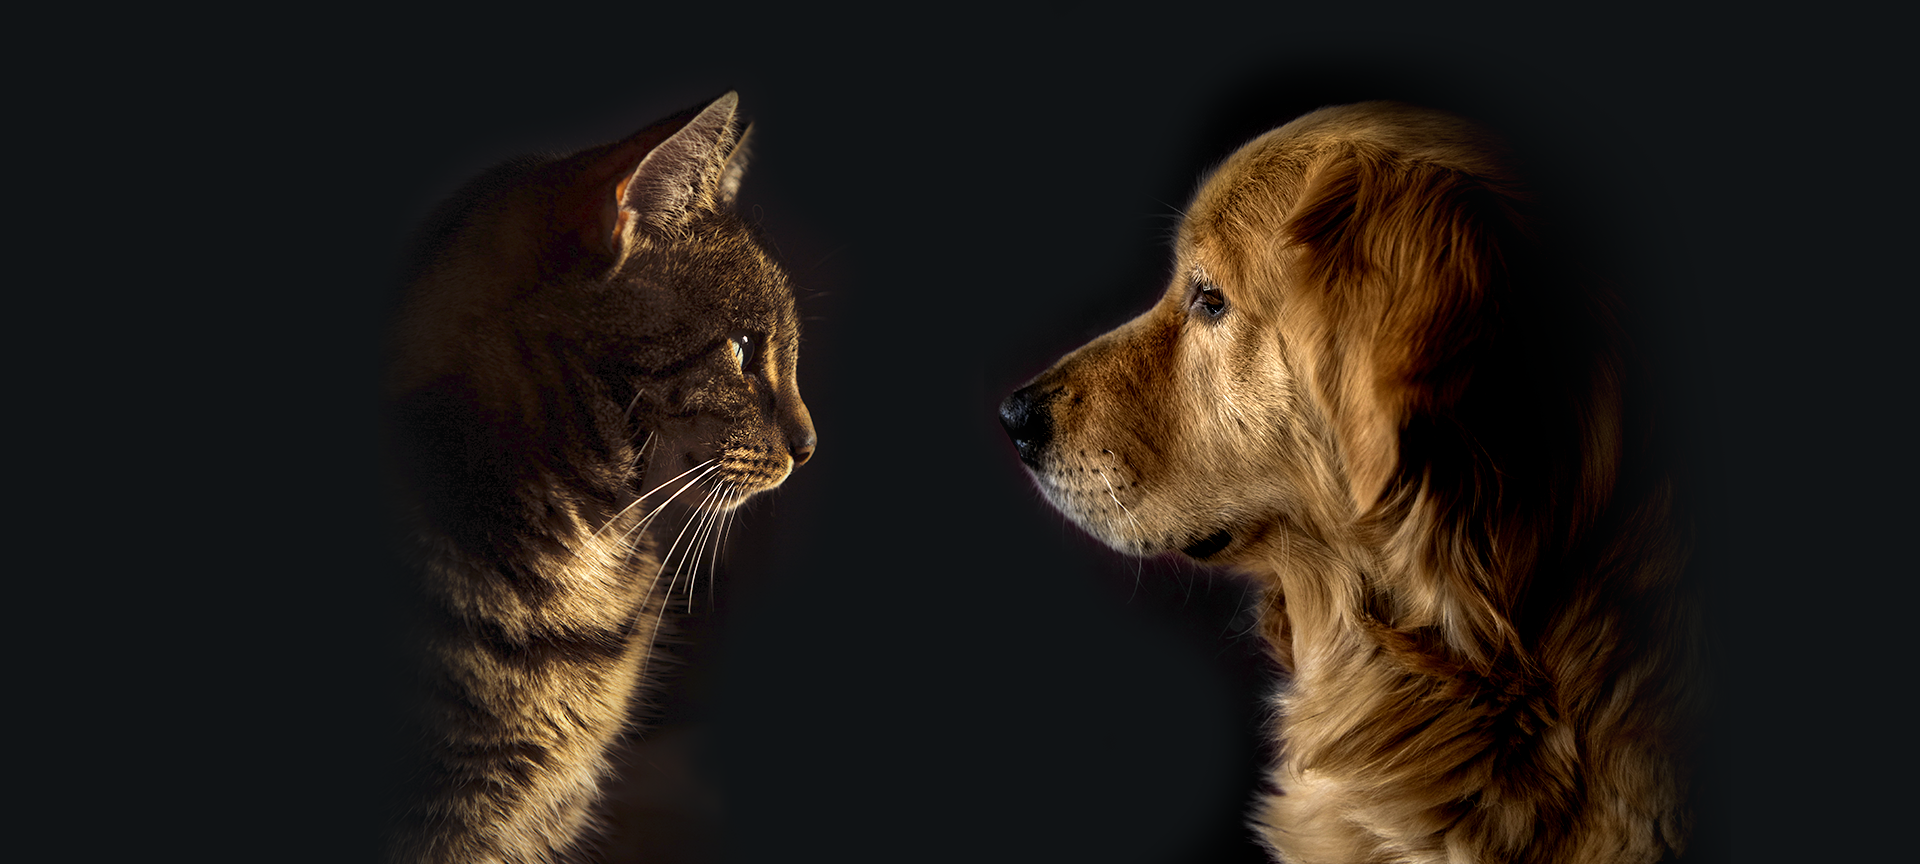

Primero, vamos a importar las bibliotecas necesarias:

In [1]:
%pip install ipykernel
%pip install opencv-python
%pip install keras
%pip install scikit-learn
%pip install tensorflow
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import hashlib
import zipfile
import tarfile
import shutil
import urllib.request
from collections import Counter
from datetime import datetime
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import keras
from keras.applications import VGG16
from keras.applications.vgg16 import preprocess_input
from keras.models import Sequential
from keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom, RandomTranslation
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

Configuramos las rutas de la base de datos y verificamos su contenido:

In [3]:
# ---------------- Configuración ----------------
DATA_DIR = 'datasets'
PERSONA_DIR = os.path.join(DATA_DIR, 'fotos')      # Clase 1: fotos del estudiante
FONDO_DIR = os.path.join(DATA_DIR, 'fondos')       # Clase 0: escenas, objetos y rostros de otras personas
PRUEBA_DIR = os.path.join(DATA_DIR, 'prueba')      # Imágenes de las 3 pruebas (nunca se usan para entrenar)
NOMBRE_ESTUDIANTE = 'Jose'                         # Etiqueta de salida para la clase del estudiante
CLASS_NAMES = ['Fondo', NOMBRE_ESTUDIANTE]         # Índice = etiqueta: 0 = Fondo, 1 = estudiante
ENTRENAR = False                                    # False: no se reentrena; se usa el modelo guardado en MODEL_PATH
MODEL_PATH = 'modelo_estudiante_fondo.keras'
TAU = 0.75                                         # Umbral de decisión sobre P(estudiante), elegido con las pruebas
IMG_SIZE = 224
USE_FACE_CROP = True                               # Si se detecta un rostro, el modelo recibe solo la región del rostro
FACE_MARGIN = 1.6                                  # Lado del recorte = 1.6 x lado mayor de la caja del rostro (cabello, lentes, mentón)
FACE_RES = 112                                     # Resolución intermedia del recorte: iguala la nitidez entre fuentes
SEED = 42
REPORT_PATH = 'reporte_actividad.txt'              # Todo lo que se registra con log() queda también en este .txt
N_CALTECH_FACES = 60                               # Rostros de otras personas (Caltech-101/Faces) que se añaden a fondos
N_LFW_TRAIN = 60                                   # Rostros LFW (1 por persona) que se añaden a fondos
N_LFW_PRUEBA = 15                                  # Rostros LFW de OTRAS personas para simular la prueba 3 (prueba/rostros)
N_BG_PRUEBA = 15                                   # BACKGROUND_Google no usados en fondos para simular la prueba 2 (prueba/fondo)
N_BG_TRAIN = 80                                    # Máximo de imágenes de BACKGROUND_Google usadas para entrenar (fondos fáciles)
# Nota: no cambiar N_LFW_TRAIN / N_LFW_PRUEBA después de la primera extracción (las identidades de entrenamiento y prueba dejarían de ser disjuntas)
keras.utils.set_random_seed(SEED)                  # Reproducibilidad (inicialización, aumento de datos, splits)

open(REPORT_PATH, 'w', encoding='utf-8').close()
def log(*args):
    msg = ' '.join(str(a) for a in args)
    print(msg)
    with open(REPORT_PATH, 'a', encoding='utf-8') as f:
        f.write(msg + '\n')

def read_image(path):
    # Lectura con PIL: aplica la orientación EXIF (fotos de celular) y admite rutas con tildes/ñ en Windows.
    # Devuelve BGR uint8 (misma convención que cv2.imread) o None si el archivo no es una imagen legible.
    try:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert('RGB')
            return cv2.cvtColor(np.asarray(im), cv2.COLOR_RGB2BGR)
    except Exception:
        return None

def square_crop(img):
    # Recorte cuadrado centrado: al pasar a 224x224 no se deforma el rostro y desaparece la diferencia
    # de proporción (vertical/horizontal) entre fotos, fondos y webcam, que el modelo podría usar como atajo
    h, w = img.shape[:2]
    s = min(h, w)
    y0, x0 = (h - s) // 2, (w - s) // 2
    return img[y0:y0 + s, x0:x0 + s]

def file_md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def source_of(path):
    # Origen de cada imagen de fondo según su nombre de archivo (para el diagnóstico y el análisis de errores)
    name = os.path.basename(str(path))
    if name.startswith('caltech_faces_'):
        return 'rostros Caltech'
    if name.startswith('lfw_'):
        return 'rostros LFW'
    if name.startswith('image_'):
        return 'BACKGROUND_Google'
    if name.startswith('WIN_'):
        return 'cuarto vacío (webcam)'
    return 'otros'

# ---------------- Ampliación de fondos con rostros de otras personas ----------------
# Negativos difíciles para la prueba 3: retratos de otras personas, extraídos del .zip de Caltech-101 sin descomprimirlo
def add_caltech_faces(zip_path, out_dir, n, seed):
    with zipfile.ZipFile(zip_path) as zf:
        members = sorted(m for m in zf.namelist() if m.startswith('caltech-101/Faces/') and m.lower().endswith('.jpg'))
        chosen = np.random.default_rng(seed).permutation(members)[:n]   # Permutación fija: ampliar n conserva los ya elegidos
        added = 0
        for m in chosen:
            dst = os.path.join(out_dir, 'caltech_faces_' + os.path.basename(m))
            if not os.path.exists(dst):
                with open(dst, 'wb') as f:
                    f.write(zf.read(m))
                added += 1
    log(f'Caltech-101/Faces: {len(members)} disponibles | seleccionadas: {len(chosen)} | nuevas copiadas a {out_dir}: {added}')

add_caltech_faces(os.path.join(DATA_DIR, 'archive.zip'), FONDO_DIR, N_CALTECH_FACES, SEED)

# Rostros de Labeled Faces in the Wild (figuras públicas): identidades distintas para entrenamiento (fondos) y para prueba/rostros
def add_lfw_faces(tgz_path, train_dir, prueba_dir, n_train, n_prueba, seed):
    os.makedirs(prueba_dir, exist_ok=True)
    have_train = sum(f.startswith('lfw_') for f in os.listdir(train_dir))
    have_prueba = sum(f.startswith('lfw_') for f in os.listdir(prueba_dir))
    if have_train >= n_train and have_prueba >= n_prueba:
        log(f'LFW: ya extraídos ({have_train} en {train_dir}, {have_prueba} en {prueba_dir})')
        return
    if not os.path.isfile(tgz_path):
        log('LFW: no se encontró', tgz_path, '-> se omite')
        return
    with tarfile.open(tgz_path, 'r:gz') as tf:
        by_person = {}
        for m in tf.getmembers():
            if m.isfile() and m.name.lower().endswith('.jpg'):
                by_person.setdefault(m.name.split('/')[-2], []).append(m)
        persons = np.random.default_rng(seed).permutation(sorted(by_person))
        first = lambda p: sorted(by_person[p], key=lambda m: m.name)[0]     # Primera imagen de cada persona
        plan = [(first(p), train_dir) for p in persons[:n_train]] + \
               [(first(p), prueba_dir) for p in persons[n_train:n_train + n_prueba]]
        added = 0
        for m, dst_dir in sorted(plan, key=lambda x: x[0].offset_data):   # Orden del archivo: lectura secuencial del .tgz
            dst = os.path.join(dst_dir, 'lfw_' + os.path.basename(m.name))
            if not os.path.exists(dst):
                with open(dst, 'wb') as f:
                    f.write(tf.extractfile(m).read())
                added += 1
    log(f'LFW: {len(by_person)} personas | {n_train} -> {train_dir} | {n_prueba} -> {prueba_dir} (identidades disjuntas) | nuevas: {added}')

# Fondos de BACKGROUND_Google que NO están en datasets/fondos, para simular la prueba 2
def add_bg_prueba(bg_dir, fondo_dir, prueba_dir, n, seed):
    os.makedirs(prueba_dir, exist_ok=True)
    have = sum(f.startswith('bg_') for f in os.listdir(prueba_dir))
    if have >= n or not os.path.isdir(bg_dir):
        log(f'BACKGROUND_Google -> prueba: {have} existentes', '' if os.path.isdir(bg_dir) else f'({bg_dir} no existe)')
        return
    used = {file_md5(os.path.join(fondo_dir, f)) for f in os.listdir(fondo_dir) if os.path.isfile(os.path.join(fondo_dir, f))}
    cand = sorted(f for f in os.listdir(bg_dir) if f.lower().endswith('.jpg') and file_md5(os.path.join(bg_dir, f)) not in used)
    for f in np.random.default_rng(seed).permutation(cand)[:n]:
        dst = os.path.join(prueba_dir, 'bg_' + f)
        if not os.path.exists(dst):
            shutil.copy2(os.path.join(bg_dir, f), dst)
    log(f'BACKGROUND_Google -> prueba: {len(cand)} no usados en fondos | copiados a {prueba_dir}: {min(n, len(cand))}')

add_lfw_faces(os.path.join(DATA_DIR, 'lfw.tgz'), FONDO_DIR, os.path.join(PRUEBA_DIR, 'rostros'), N_LFW_TRAIN, N_LFW_PRUEBA, SEED)
add_bg_prueba(os.path.join(DATA_DIR, 'BACKGROUND_Google'), FONDO_DIR, os.path.join(PRUEBA_DIR, 'fondo'), N_BG_PRUEBA, SEED)

# ---------------- Detector de rostros ----------------
# Se usa para el diagnóstico y para recortar el rostro antes de clasificar (USE_FACE_CROP).
# OpenCV 4.x trae CascadeClassifier (Haar); OpenCV 5.x lo eliminó, así que se usa YuNet (cv2.FaceDetectorYN),
# cuyo modelo ONNX (~230 KB) se descarga una sola vez a datasets/. Si nada está disponible, no se recorta el rostro.
YUNET_URL = 'https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx'

def make_face_detector():
    xml = os.path.join(getattr(getattr(cv2, 'data', None), 'haarcascades', ''), 'haarcascade_frontalface_default.xml')
    if hasattr(cv2, 'CascadeClassifier') and os.path.isfile(xml):
        cascade = cv2.CascadeClassifier(xml)
        def detect(img):
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
            return [tuple(map(float, b)) for b in cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))]
        return 'Haar', detect
    if hasattr(cv2, 'FaceDetectorYN'):
        model_path = os.path.join(DATA_DIR, 'face_detection_yunet_2023mar.onnx')
        try:
            if not os.path.isfile(model_path):
                urllib.request.urlretrieve(YUNET_URL, model_path)
            detector = cv2.FaceDetectorYN.create(model_path, '', (320, 320), 0.8, 0.3, 5000)
            def detect(img):
                detector.setInputSize((img.shape[1], img.shape[0]))
                _, faces = detector.detect(img)
                return [] if faces is None else [tuple(map(float, f[:4])) for f in faces]
            return 'YuNet', detect
        except Exception as e:
            if os.path.isfile(model_path):
                os.remove(model_path)      # Evita dejar un archivo de modelo incompleto para la siguiente ejecución
            log('No se pudo preparar YuNet:', repr(e))
    return None, None

FACE_METHOD, _face_detect = make_face_detector()
log('cv2', cv2.__version__, '| detector de rostros:', FACE_METHOD, '| recorte de rostro:', USE_FACE_CROP and FACE_METHOD is not None)

def detect_faces(img):
    # Detección sobre una versión reducida (lado mayor <= 640 px); devuelve cajas (x, y, w, h) en coordenadas originales
    if FACE_METHOD is None:
        return []
    scale = min(1.0, 640 / max(img.shape[:2]))
    small = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale < 1 else img
    return [(x / scale, y / scale, w / scale, h / scale) for x, y, w, h in _face_detect(np.ascontiguousarray(small))]

def count_faces(img):
    return len(detect_faces(img))

def face_crop(img):
    # Recorte cuadrado centrado en el rostro más grande; None si no hay rostro.
    # Elimina el contexto (cuarto, encuadre, fondo) para que el modelo se base en el rostro
    boxes = detect_faces(img)
    if not boxes:
        return None
    x, y, w, h = max(boxes, key=lambda b: b[2] * b[3])
    s = int(round(FACE_MARGIN * max(w, h)))
    x0, y0 = int(round(x + w / 2 - s / 2)), int(round(y + h / 2 - s / 2))
    H, W = img.shape[:2]
    pad = max(0, -x0, -y0, x0 + s - W, y0 + s - H)
    if pad:   # Si el recorte sale de la imagen, se extienden los bordes
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_REPLICATE)
        x0, y0 = x0 + pad, y0 + pad
    return img[y0:y0 + s, x0:x0 + s]

# ---------------- Verificación de la base de datos ----------------
def inspect_folder(folder, name):
    files = [f for f in sorted(os.listdir(folder)) if os.path.isfile(os.path.join(folder, f))]
    hashes, unreadable, shapes, orient, n_gray = {}, [], [], Counter(), 0
    faces_full, faces_crop, no_face, lost_by_crop = [], [], [], []
    for f in files:
        path = os.path.join(folder, f)
        img = read_image(path)
        if img is None:
            unreadable.append(f)
            continue
        hashes.setdefault(file_md5(path), []).append(f)
        h, w = img.shape[:2]
        shapes.append((h, w))
        orient['vertical' if h > 1.05 * w else 'horizontal' if w > 1.05 * h else 'cuadrada'] += 1
        small = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA).astype(int)
        n_gray += int(np.abs(small[..., 0] - small[..., 1]).max() < 8 and np.abs(small[..., 1] - small[..., 2]).max() < 8)
        if FACE_METHOD is not None:
            n_full, n_crop = count_faces(img), count_faces(square_crop(img))
            faces_full.append(n_full)
            faces_crop.append(n_crop)
            if n_full == 0:
                no_face.append(f)
            elif n_crop == 0:
                lost_by_crop.append(f)
    hw = np.array(shapes)
    ff = np.array(faces_full)
    log(f'\n=== {name}: {folder} ===')
    log('archivos:', len(files), '| legibles:', len(shapes), '| extensiones:', dict(Counter(os.path.splitext(f)[1].lower() for f in files)))
    log('ilegibles:', unreadable)
    log('duplicados exactos:', [v for v in hashes.values() if len(v) > 1])
    if len(hw):
        log(f'alto  min/mediana/max: {hw[:, 0].min()}/{int(np.median(hw[:, 0]))}/{hw[:, 0].max()}')
        log(f'ancho min/mediana/max: {hw[:, 1].min()}/{int(np.median(hw[:, 1]))}/{hw[:, 1].max()}')
        log('orientación:', dict(orient), '| en escala de grises:', n_gray)
        if name == 'FONDO':
            log('composición por origen:', dict(Counter(source_of(f) for f in files)))
    if len(ff):
        log(f'rostros detectados ({FACE_METHOD}, aprox.): 0 -> {int((ff == 0).sum())} | 1 -> {int((ff == 1).sum())} | >=2 -> {int((ff >= 2).sum())}')
        log(f'imágenes sin rostro detectado ({len(no_face)}):', no_face if name == 'ESTUDIANTE' else no_face[:10])
        log(f'imágenes cuyo rostro se pierde con el recorte cuadrado ({len(lost_by_crop)}):', lost_by_crop)
    return hashes

log('Reporte generado:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
h_persona = inspect_folder(PERSONA_DIR, 'ESTUDIANTE')
h_fondo = inspect_folder(FONDO_DIR, 'FONDO')

log('\n=== Verificaciones cruzadas ===')
log('imágenes repetidas entre fotos y fondos (no debe haber):', [h_persona[k] for k in set(h_persona) & set(h_fondo)])
bg_dir = os.path.join(DATA_DIR, 'BACKGROUND_Google')
if os.path.isdir(bg_dir):
    h_bg = {file_md5(os.path.join(bg_dir, f)) for f in os.listdir(bg_dir) if os.path.isfile(os.path.join(bg_dir, f))}
    from_bg = sum(len(v) for k, v in h_fondo.items() if k in h_bg)
    log(f'BACKGROUND_Google: {len(h_bg)} imágenes | fondos que provienen de ahí: {from_bg} de {sum(len(v) for v in h_fondo.values())}')
zip_path = os.path.join(DATA_DIR, 'archive.zip')
if os.path.isfile(zip_path):
    with zipfile.ZipFile(zip_path) as zf:
        infos = [i for i in zf.infolist() if not i.is_dir()]
        tops = Counter('/'.join(i.filename.split('/')[:2]) for i in infos)
        log(f'archive.zip: {len(infos)} archivos, {sum(i.file_size for i in infos) / 2**20:.1f} MB descomprimido | primeros niveles:', dict(tops.most_common(10)))
log('carpeta de pruebas:', {d: len(os.listdir(os.path.join(PRUEBA_DIR, d))) for d in os.listdir(PRUEBA_DIR) if os.path.isdir(os.path.join(PRUEBA_DIR, d))} if os.path.isdir(PRUEBA_DIR) else 'no existe todavía')

Caltech-101/Faces: 435 disponibles | seleccionadas: 60 | nuevas copiadas a datasets\fondos: 0
LFW: ya extraídos (60 en datasets\fondos, 15 en datasets\prueba\rostros)
BACKGROUND_Google -> prueba: 15 existentes 
cv2 5.0.0 | detector de rostros: YuNet | recorte de rostro: True
Reporte generado: 2026-11-09 20:22:58

=== ESTUDIANTE: datasets\fotos ===
archivos: 65 | legibles: 65 | extensiones: {'.jpg': 65}
ilegibles: []
duplicados exactos: []
alto  min/mediana/max: 176/1080/3264
ancho min/mediana/max: 132/1920/3264
orientación: {'vertical': 18, 'horizontal': 47} | en escala de grises: 0
rostros detectados (YuNet, aprox.): 0 -> 0 | 1 -> 65 | >=2 -> 0
imágenes sin rostro detectado (0): []
imágenes cuyo rostro se pierde con el recorte cuadrado (0): []

=== FONDO: datasets\fondos ===
archivos: 280 | legibles: 280 | extensiones: {'.jpg': 274, '.jpeg': 6}
ilegibles: []
duplicados exactos: []
alto  min/mediana/max: 141/298/5068
ancho min/mediana/max: 140/337/3481
orientación: {'vertical': 60, 'ho

Cargamos las imágenes del estudiante y de los fondos:

fondos usados por origen: {'otros': 10, 'cuarto vacío (webcam)': 3, 'rostros Caltech': 60, 'BACKGROUND_Google': 80, 'rostros LFW': 60}
recorte de rostro aplicado -> estudiante: 65/65
recorte de rostro aplicado -> fondos BACKGROUND_Google     : 12/80
recorte de rostro aplicado -> fondos cuarto vacío (webcam) : 0/3
recorte de rostro aplicado -> fondos otros                 : 10/10
recorte de rostro aplicado -> fondos rostros Caltech       : 60/60
recorte de rostro aplicado -> fondos rostros LFW           : 60/60


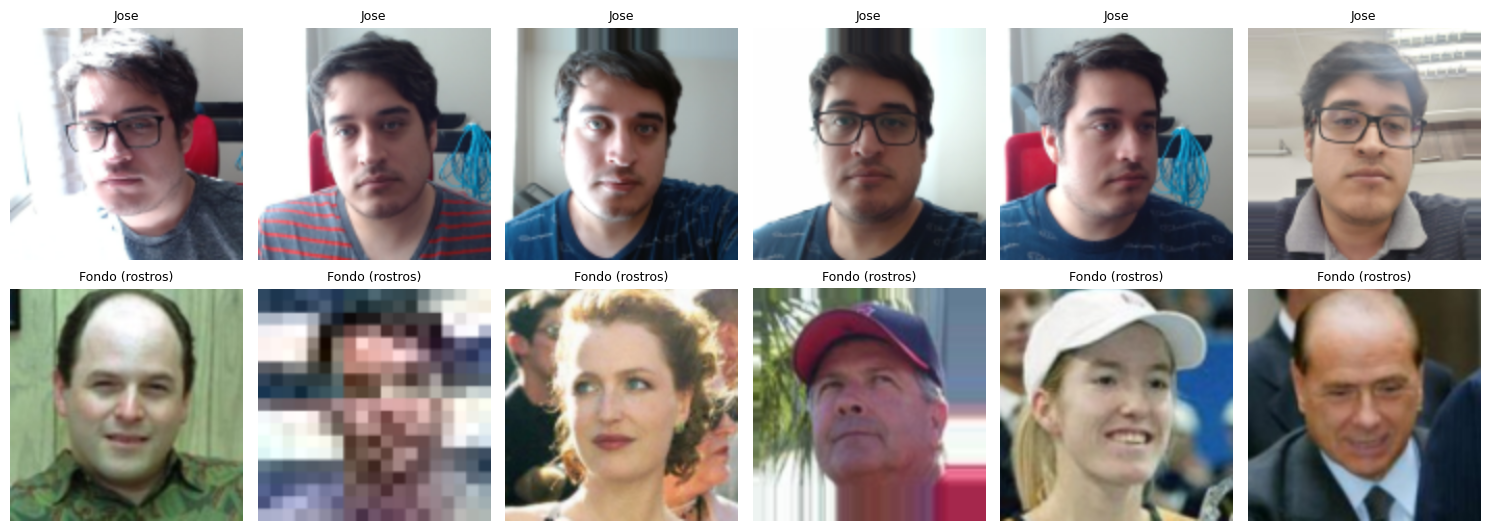


images: (278, 224, 224, 3) | labels: (278,) | estudiante/fondo: [ 65 213]


array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [4]:
def prepare_image(img_bgr, return_info=False):
    # Mismo procesamiento en entrenamiento y en predicción:
    # - con rostro: recorte del rostro -> 112x112 (iguala nitidez entre fuentes) -> 224x224
    # - sin rostro: recorte cuadrado centrado -> 224x224 (dimensión de entrada de VGG-16)
    face = face_crop(img_bgr) if USE_FACE_CROP else None
    if face is not None:
        img = cv2.resize(face, (FACE_RES, FACE_RES), interpolation=cv2.INTER_AREA)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    else:
        img = cv2.resize(square_crop(img_bgr), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return (img, face is not None) if return_info else img

def load_images(folder, label, keep=None):
    # Inicializamos las listas para almacenar las imágenes, las etiquetas, las rutas (para analizar errores)
    # y si se recortó un rostro
    images, labels, paths, used_face = [], [], [], []

    # Iteramos sobre cada archivo en la carpeta especificada (keep: filtro opcional por nombre de archivo)
    for filename in sorted(os.listdir(folder)):
        if keep is not None and not keep(filename):
            continue
        path = os.path.join(folder, filename)
        img = read_image(path)

        # Si la imagen se ha leído correctamente, la procesamos y le asignamos la etiqueta de su clase
        if img is not None:
            prep, has_face = prepare_image(img, return_info=True)
            images.append(prep)
            labels.append(label)
            paths.append(path)
            used_face.append(has_face)

    return images, labels, paths, used_face

# Cargamos las imágenes del estudiante (etiqueta 1) y de los fondos (etiqueta 0)
persona_images, persona_labels, persona_paths, persona_face = load_images(PERSONA_DIR, 1)
# De BACKGROUND_Google (fondos fáciles) se usa un subconjunto fijo de N_BG_TRAIN imágenes para no desbalancear las clases
bg_files = sorted(f for f in os.listdir(FONDO_DIR) if source_of(f) == 'BACKGROUND_Google')
bg_keep = set(np.random.default_rng(SEED).permutation(bg_files)[:N_BG_TRAIN])
fondo_images, fondo_labels, fondo_paths, fondo_face = load_images(FONDO_DIR, 0, keep=lambda f: source_of(f) != 'BACKGROUND_Google' or f in bg_keep)
log('fondos usados por origen:', dict(Counter(source_of(p) for p in fondo_paths)))
log(f'recorte de rostro aplicado -> estudiante: {sum(persona_face)}/{len(persona_face)}')
for src in sorted(set(source_of(p) for p in fondo_paths)):
    flags = [f for p, f in zip(fondo_paths, fondo_face) if source_of(p) == src]
    log(f'recorte de rostro aplicado -> fondos {src:22s}: {sum(flags)}/{len(flags)}')

# Visualizamos una muestra tal como la recibe el modelo (tras el recorte y redimensionado)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
fondo_face_imgs = [im for im, f in zip(fondo_images, fondo_face) if f]
for row, (imgs, name) in enumerate([(persona_images, NOMBRE_ESTUDIANTE), (fondo_face_imgs or fondo_images, 'Fondo (rostros)')]):
    for ax, idx in zip(axes[row], rng.choice(len(imgs), size=min(6, len(imgs)), replace=False)):
        ax.imshow(imgs[idx])
        ax.set_title(name, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.savefig('muestras_dataset.png', dpi=80)
plt.show()

# Combinamos los arrays del estudiante y de los fondos
images = np.array(persona_images + fondo_images)
labels = np.array(persona_labels + fondo_labels)
paths = np.array(persona_paths + fondo_paths)

# Preprocesado estándar de VGG-16 (RGB->BGR y resta de la media de ImageNet), el mismo usado al preentrenar la red
images = preprocess_input(images.astype('float32'))
log('\nimages:', images.shape, '| labels:', labels.shape, '| estudiante/fondo:', np.bincount(labels)[::-1])
labels

In [5]:
# One-hot encoding de las etiquetas
labels = to_categorical(labels) # Convertimos las etiquetas a formato one-hot: 0 -> [1, 0] (Fondo), 1 -> [0, 1] (estudiante)
labels

array([[0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.],
       [0., 1.

Dividimos los datos en conjuntos de entrenamiento, validación y prueba:

In [6]:
# Test (20%) estratificado; del resto, 20% estratificado para validación (lo usa EarlyStopping)
X_train, X_test, y_train, y_test, p_train, p_test = train_test_split(images, labels, paths, test_size=0.2, stratify=labels, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)

# Pesos por clase para compensar el desbalance estudiante/fondo: w_c = N / (2 * N_c)
n_c = y_fit.sum(axis=0)
class_weight = {c: float(len(y_fit) / (2 * n_c[c])) for c in range(2)}

for name, y in [('fit', y_fit), ('val', y_val), ('test', y_test)]:
    log(f'{name:5s}: {len(y)} imágenes | fondo/estudiante: {y.sum(axis=0).astype(int)}')
log('class_weight:', {CLASS_NAMES[c]: round(w, 3) for c, w in class_weight.items()})

fit  : 177 imágenes | fondo/estudiante: [136  41]
val  : 45 imágenes | fondo/estudiante: [34 11]
test : 56 imágenes | fondo/estudiante: [43 13]
class_weight: {'Fondo': 0.651, 'Jose': 2.159}


Construimos y entrenamos la red neuronal convolucional VGG-16:

In [7]:
if ENTRENAR:
    # Definimos el callback de EarlyStopping (restaura los pesos de la época con menor val_loss).
    # patience=15: la validación tiene pocas fotos del estudiante y val_loss es ruidosa
    early_stopping = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

    # Cargamos la red VGG16, asegurándonos de que se dejan fuera las capas superiores de la red preentrenada (head FC layer)
    baseModel = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

    # Construimos el modelo
    model = Sequential()
    model.add(Input(shape=(IMG_SIZE, IMG_SIZE, 3)))
    # Aumento de datos: solo actúa durante el entrenamiento. Se usan solo transformaciones geométricas porque las
    # entradas ya están preprocesadas (valores negativos) y las capas de brillo/contraste recortan al rango [0, 255]
    model.add(RandomFlip('horizontal'))
    model.add(RandomRotation(0.05))            # ±18°
    model.add(RandomZoom(0.1))
    model.add(RandomTranslation(0.05, 0.05))
    model.add(baseModel)
    # GlobalAveragePooling2D en lugar de Flatten: 512 features en vez de 25 088 (de ~6.4 M a ~131 k parámetros entrenables),
    # menos sobreajuste y logits de menor magnitud -> probabilidades no saturadas, necesarias para ajustar el umbral TAU
    model.add(GlobalAveragePooling2D())
    model.add(Dense(256, activation='relu'))
    model.add(Dropout(0.5))  # Agregamos una capa de Dropout con una tasa de 0.5
    model.add(Dense(2, activation='softmax'))  # Dos clases (fondo y estudiante), por lo que la capa de salida tiene 2 neuronas

    # Congelamos las capas del modelo base para que no se actualicen durante el entrenamiento
    for layer in baseModel.layers:
        layer.trainable = False

    # Compilamos el modelo (Adam con tasa de aprendizaje 1e-4 en lugar de 1e-3 por defecto, para un ajuste más gradual)
    model.compile(loss='categorical_crossentropy', optimizer=keras.optimizers.Adam(learning_rate=1e-4), metrics=['accuracy'])

    # Entrenamos el modelo (validación separada; X_test queda reservado para la evaluación final)
    history = model.fit(X_fit, y_fit, validation_data=(X_val, y_val), epochs=300, batch_size=32,
                        callbacks=[early_stopping], class_weight=class_weight)

    # Registramos la evolución del entrenamiento
    h = history.history
    log('\n=== Entrenamiento ===')
    for e in range(len(h['loss'])):
        log(f"época {e + 1:3d}: loss={h['loss'][e]:.4f} acc={h['accuracy'][e]:.4f} val_loss={h['val_loss'][e]:.4f} val_acc={h['val_accuracy'][e]:.4f}")
    log('mejor época (pesos restaurados):', int(np.argmin(h['val_loss'])) + 1)
else:
    # Sin reentrenar: se usa el modelo ya guardado (resultados estables entre ejecuciones)
    model = keras.models.load_model(MODEL_PATH)
    h = None
    log(f'\n=== Modelo cargado desde {MODEL_PATH} (sin reentrenar) ===')

# Evaluamos el modelo
loss, accuracy = model.evaluate(X_test, y_test)
log(f'Loss: {loss}')
log(f'Accuracy: {accuracy}')


=== Modelo cargado desde modelo_estudiante_fondo.keras (sin reentrenar) ===
2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 817ms/step - accuracy: 0.9643 - loss: 0.1286
Loss: 0.12859998643398285
Accuracy: 0.9642857313156128


Evaluamos el modelo en detalle sobre el conjunto de prueba (matriz de confusión, errores y umbral de decisión):

In [8]:
probs = model.predict(X_test, verbose=0)
p_est = probs[:, 1]                       # Probabilidad de que la imagen sea del estudiante
y_true = y_test.argmax(axis=1)
y_pred = (p_est >= TAU).astype(int)

log(f'\n=== Evaluación en test (TAU = {TAU}) ===')
log('matriz de confusión (filas = real, columnas = predicho) [Fondo, estudiante]:')
log(confusion_matrix(y_true, y_pred, labels=[0, 1]))
log(classification_report(y_true, y_pred, labels=[0, 1], target_names=CLASS_NAMES, digits=3, zero_division=0))
log('errores (ruta | real | P(estudiante)):')
for i in np.where(y_true != y_pred)[0]:
    log(f'  {p_test[i]} | {CLASS_NAMES[y_true[i]]} | {p_est[i]:.3f}')

# Separación entre clases: si max(P) de los fondos < min(P) del estudiante, existe un umbral que separa ambas clases
p_pos, p_neg = p_est[y_true == 1], p_est[y_true == 0]
log('P(estudiante) de cada foto del estudiante en test:', [f'{os.path.basename(p)}={v:.3f}' for p, v in sorted(zip(p_test[y_true == 1], p_pos), key=lambda t: t[1])])
log('5 fondos con mayor P(estudiante) en test:', [f'{os.path.basename(p)}={v:.3f}' for p, v in sorted(zip(p_test[y_true == 0], p_neg), key=lambda t: -t[1])[:5]])
log(f'P(estudiante) en fotos del estudiante: min={p_pos.min():.3f} mediana={np.median(p_pos):.3f}')
log(f'P(estudiante) en fondos:               max={p_neg.max():.3f} mediana={np.median(p_neg):.3f}')
src_test = np.array([source_of(p) for p in p_test])
for src in sorted(set(src_test[y_true == 0])):
    p_src = p_est[(y_true == 0) & (src_test == src)]
    log(f'   fondos de origen {src:22s}: n={len(p_src):3d} | P(estudiante) max={p_src.max():.3f} media={p_src.mean():.3f}')

# Curvas de entrenamiento (solo si se entrenó en esta ejecución)
if h is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(h[metric], label='fit')
        ax.plot(h['val_' + metric], label='val')
        ax.set_xlabel('época')
        ax.set_title(metric)
        ax.legend()
    plt.tight_layout()
    plt.savefig('curvas_entrenamiento.png', dpi=80)
    plt.show()


=== Evaluación en test (TAU = 0.75) ===
matriz de confusión (filas = real, columnas = predicho) [Fondo, estudiante]:
[[41  2]
 [ 0 13]]
              precision    recall  f1-score   support

       Fondo      1.000     0.953     0.976        43
        Jose      0.867     1.000     0.929        13

    accuracy                          0.964        56
   macro avg      0.933     0.977     0.952        56
weighted avg      0.969     0.964     0.965        56

errores (ruta | real | P(estudiante)):
  datasets\fondos\caltech_faces_image_0003.jpg | Fondo | 0.988
  datasets\fondos\caltech_faces_image_0300.jpg | Fondo | 0.850
P(estudiante) de cada foto del estudiante en test: ['20240316_085101.jpg=0.958', '20230714_081904.jpg=0.985', 'WIN_20261108_11_46_18_Pro.jpg=0.988', '20240611_121622~2.jpg=0.988', '20230823_081218.jpg=0.995', 'WIN_20261108_10_20_26_Pro.jpg=0.997', 'WIN_20261108_10_09_22_Pro.jpg=0.997', 'WIN_20261108_10_10_53_Pro.jpg=0.998', 'WIN_20261108_10_09_17_Pro.jpg=0.998', 'WIN_2

**Opcional:** Guardamos el modelo en un archivo formato .keras (formato nativo; .h5 es legacy) y lo cargamos en el dispositivo de despliegue

In [9]:
# Exportamos el modelo en formato .keras (solo si se entrenó en esta ejecución, para no sobrescribir un modelo validado)
if ENTRENAR:
    model.save(MODEL_PATH)

In [10]:
# Cargamos el modelo desde un archivo formato .keras
from keras.models import load_model
model = load_model(MODEL_PATH)

Hacemos una predicción con una nueva imagen para comprobar que el modelo funciona

In [11]:
# El umbral de decisión TAU sobre P(estudiante) se define en la celda de configuración
def predict_image(img_bgr):
    # Aplicamos exactamente el mismo procesamiento que en entrenamiento y expandimos a un lote de forma (1, 224, 224, 3)
    x = np.expand_dims(prepare_image(img_bgr).astype('float32'), axis=0)
    x = preprocess_input(x)
    pred = model.predict(x, verbose=0)
    label = NOMBRE_ESTUDIANTE if pred[0][1] >= TAU else 'Fondo'
    return pred, label

# Imagen nunca vista en el entrenamiento (por defecto, la primera del conjunto de test; puede reemplazarse por cualquier ruta)
TEST_IMAGE = os.path.join(PRUEBA_DIR, 'webcam', 'webcam_20261108_113023.jpg')
img = read_image(TEST_IMAGE)
assert img is not None, f'No se pudo leer {TEST_IMAGE}'

# Realizamos la predicción e imprimimos el resultado
pred, label = predict_image(img)
log(TEST_IMAGE, pred, label)

datasets\prueba\webcam\webcam_20261108_113023.jpg [[7.5043325e-05 9.9992490e-01]] Jose


Aunque `img` sea una sola imagen, el modelo siempre espera un lote (batch), y también devuelve un lote de predicciones.

`pred[0][0]` corresponde a la probabilidad de que la imagen sea un fondo

`pred[0][1]` corresponde a la probabilidad de que la imagen sea del estudiante

La razón por la que siempre se utiliza `[0]` al inicio en `pred[0][0]` y `pred[0][1]` es porque el método predict de un modelo de Keras devuelve una matriz de predicciones, incluso si solo se pasa una imagen para la predicción.

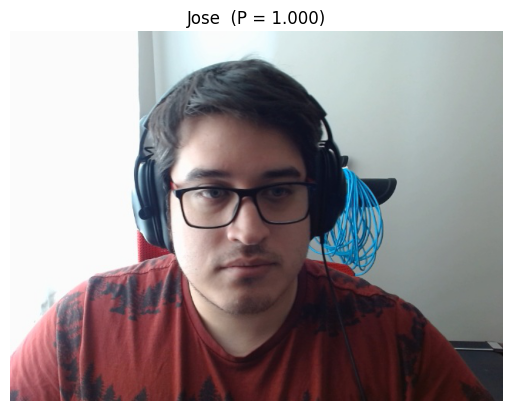

In [12]:
# Convertimos la imagen de BGR (convención de OpenCV) a RGB (formato utilizado por Matplotlib)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

# Mostramos la etiqueta predicha y la probabilidad de que sea el estudiante
plt.title(f'{label}  (P = {pred[0][1]:.3f})')

# Ocultamos los ejes de la imagen
plt.axis('off')
# Mostramos la imagen con la predicción
plt.show()

## Actividad calificable:

En esta actividad, llevaremos a cabo una serie de pruebas para evaluar la capacidad de nuestro modelo de clasificación de imágenes. El objetivo es identificar correctamente si una imagen contiene el rostro de un estudiante específico o si pertenece a un fondo. Para ello, hemos definido dos etiquetas principales:

##### **Label 1:** `Nombre del estudiante`  
##### **Label 2:** `Fondo` (imagenes que no contengan el rostro del estudiante)

#### **Pruebas:**

Las pruebas se realizarán con diferentes tipos de imágenes de entrada para verificar la precisión del modelo en escenarios no vistos durante el entrenamiento:

1. **Input image:** Foto del estudiante que no se encuentre en la carpeta de entrenamiento (tómate una foto el día de la presentación usando tu webcam).
**Required output label:** `Nombre del estudiante`

2. **Input image:** Fondo que no se encuentre en la carpeta de entrenamiento (el estudiante que presente antes de ti te dará la palabra de búsqueda, puedes descargarla de Google Images).  
**Required output label:** `Fondo`
3. **Input image:** Foto de un rostro diferente al rostro del estudiante que no se encuentre en las carpetas de entrenamiento (el estudiante que presente antes de ti te dará un nombre de una celebridad que se parezca a ti, puedes descargarla de Google Images).  
**Required output label:** `Fondo`

##### **Hyperparameter testing (Opcional):**

Además, puedes explorar el impacto de varios hiperparámetros en el rendimiento del modelo. Los hiperparámetros a ajustar incluyen:

-Aumento de imágenes en la base de datos  
-Cambio de función de pérdida (loss)  
-Cambio en el optimizador (optimizer)  
-Cambio en el número de épocas de entrenamiento (epochs)  
-Cambio en el número de tamaño de lote (batch_size)

Estas pruebas y ajustes te permitirán optimizar el modelo para obtener la mejor precisión posible en la clasificación de imágenes.

##### **Presentación de resultados**

Los estudiantes presentarán sus resultados en clase usando una app de `streamlit`. La calificación dependerá del éxito de las 3 pruebas.

**Prueba 1 (webcam):** capturamos una foto, la guardamos en `datasets/prueba/webcam` y la clasificamos

datasets\prueba\webcam\webcam_20261109_202330.jpg [[0.00676113 0.9932388 ]] Jose


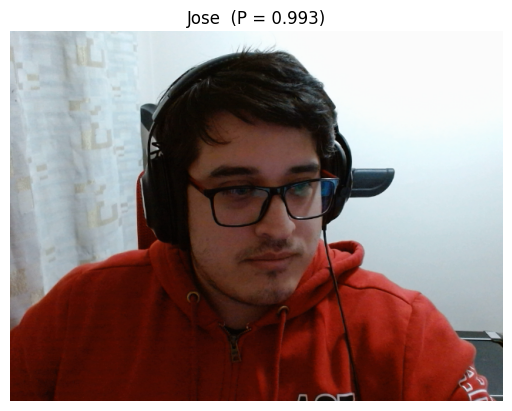

In [13]:
CAM_INDEX = 0                                  # Cambiar a 1, 2... si hay varias cámaras
cap = cv2.VideoCapture(CAM_INDEX)
assert cap.isOpened(), 'No se pudo abrir la webcam'
for _ in range(15):                            # Descartamos los primeros frames mientras se ajusta la exposición
    cap.read()
ok, frame = cap.read()
cap.release()
assert ok, 'No se pudo capturar la imagen'

os.makedirs(os.path.join(PRUEBA_DIR, 'webcam'), exist_ok=True)
cam_path = os.path.join(PRUEBA_DIR, 'webcam', datetime.now().strftime('webcam_%Y%m%d_%H%M%S.jpg'))
cv2.imwrite(cam_path, frame)

pred, label = predict_image(frame)
log(cam_path, pred, label)
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.title(f'{label}  (P = {pred[0][1]:.3f})')
plt.axis('off')
plt.show()

**Pruebas 1, 2 y 3 por lotes:** clasificamos todas las imágenes de `datasets/prueba` y las comparamos con la etiqueta esperada

In [14]:
# Subcarpeta -> etiqueta requerida
EXPECTED = {'webcam': NOMBRE_ESTUDIANTE,    # Prueba 1
            'persona': NOMBRE_ESTUDIANTE,   # Prueba 1 (fotos nuevas que no están en datasets/fotos)
            'fondo': 'Fondo',               # Prueba 2
            'rostros': 'Fondo'}             # Prueba 3 (celebridades/otras personas)

log(f'\n=== Pruebas (TAU = {TAU}) ===')
review = []   # Fallos y casos dudosos: (título, imagen tal como la recibe el modelo)
if not os.path.isdir(PRUEBA_DIR):
    log('No existe', PRUEBA_DIR)
for sub, expected in EXPECTED.items():
    folder = os.path.join(PRUEBA_DIR, sub)
    if not os.path.isdir(folder):
        continue
    n_ok = n = 0
    for f in sorted(os.listdir(folder)):
        im = read_image(os.path.join(folder, f))
        if im is None:
            continue
        p, lab = predict_image(im)
        n += 1
        n_ok += lab == expected
        log(f"{sub:8s} | {f[:45]:45s} | P(estudiante)={p[0][1]:.3f} -> {lab:12s} {'OK' if lab == expected else 'FALLO'}")
        if lab != expected or abs(p[0][1] - TAU) < 0.25:
            review.append((f"{sub}: {f[:16]}\nP={p[0][1]:.2f} {'OK' if lab == expected else 'FALLO'}", prepare_image(im)))
    log(f'>> {sub}: {n_ok}/{n} correctas')

# Errores del conjunto de test con el umbral TAU
for i in np.where(y_true != y_pred)[0]:
    review.append((f"test: {os.path.basename(p_test[i])[:16]}\nP={p_est[i]:.2f} FALLO", prepare_image(read_image(p_test[i]))))

# Cuadrícula de revisión: muestra la entrada real del modelo (recorte de rostro incluido)
"""
if review:
    cols = 6
    rows = int(np.ceil(len(review) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.9 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, (title, im_rgb) in zip(axes.ravel(), review):
        ax.imshow(im_rgb)
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.savefig('revision_pruebas.png', dpi=80)
    plt.show()"""
log(f'casos en revision_pruebas.png: {len(review)}')


=== Pruebas (TAU = 0.75) ===
webcam   | webcam_20261108_111556.jpg                    | P(estudiante)=0.990 -> Jose         OK
webcam   | webcam_20261108_113023.jpg                    | P(estudiante)=1.000 -> Jose         OK
webcam   | webcam_20261108_120222.jpg                    | P(estudiante)=0.997 -> Jose         OK
webcam   | webcam_20261108_121016.jpg                    | P(estudiante)=0.993 -> Jose         OK
webcam   | webcam_20261108_185501.jpg                    | P(estudiante)=0.999 -> Jose         OK
webcam   | webcam_20261109_192752.jpg                    | P(estudiante)=1.000 -> Jose         OK
webcam   | webcam_20261109_201234.jpg                    | P(estudiante)=1.000 -> Jose         OK
webcam   | webcam_20261109_202040.jpg                    | P(estudiante)=0.950 -> Jose         OK
webcam   | webcam_20261109_202330.jpg                    | P(estudiante)=0.992 -> Jose         OK
>> webcam: 9/9 correctas
persona  | 20240507_002032.jpg                           | P(es

presentación: D:\mcd\mcd_Fundamentos_AI\mcd_transfer_learning\datasets\presentacion\brave_nFwYtv53Zq.png [[0.99888724 0.00111283]] Fondo


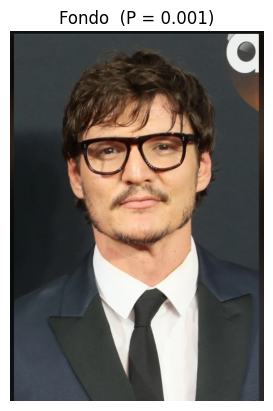

In [17]:
# Pruebas 2 y 3: cambiar solo la ruta y ejecutar únicamente esta celda
TEST_IMAGE = r'D:\mcd\mcd_Fundamentos_AI\mcd_transfer_learning\datasets\presentacion\brave_nFwYtv53Zq.png'
img = read_image(TEST_IMAGE)
assert img is not None, f'No se pudo leer {TEST_IMAGE}'
pred, label = predict_image(img)
log('presentación:', TEST_IMAGE, pred, label)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f'{label}  (P = {pred[0][1]:.3f})')
plt.axis('off')
plt.show()